In [6]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Annotated
from langchain_core.messages import BaseMessage,HumanMessage
from langchain_groq import ChatGroq
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
llm=ChatGroq(model="openai/gpt-oss-20b",temperature=0)

In [3]:
class ChatState(TypedDict):
    messages:Annotated[list[BaseMessage],add_messages]

In [4]:
def chat_node(state:ChatState):
    #take user query
    messages=state['messages']

    #send to llm
    response=llm.invoke(messages)

    #response store state
    return {'messages':[response]}

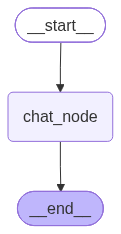

In [7]:
checkpointer=MemorySaver()

graph=StateGraph(ChatState)

graph.add_node('chat_node',chat_node)

graph.add_edge(START,'chat_node')
graph.add_edge('chat_node',END)

chatbot=graph.compile(checkpointer=checkpointer)
chatbot

In [8]:
initial_state={
    'messages':[HumanMessage(content='what is capital of india')]
}
chatbot.invoke(initial_state)

ValueError: Checkpointer requires one or more of the following 'configurable' keys: thread_id, checkpoint_ns, checkpoint_id

In [9]:
thread_id='1'
while True:
    user_message=input('type here: ')
    print('user',user_message)

    if user_message.strip().lower()in ['exit','quit','bye']:
        break

    config={'configurable':{'thread_id':thread_id}}
    response=chatbot.invoke({'messages':[HumanMessage(content=user_message)]},config=config)
    print('AI',response['messages'][-1].content)

user hii
AI Hello! How can I help you today?
user tell me about virat kohli
AI ## Virat Kohli – A Quick‑Reference Profile

| Category | Details |
|----------|---------|
| **Full name** | Virat Kohli |
| **Date of birth** | 5 November 1988 |
| **Place of birth** | Delhi, India (raised in Bangalore, Karnataka) |
| **Batting style** | Right‑handed |
| **Bowling style** | Right‑arm medium‑pace (occasional off‑spin) |
| **Primary role** | Top‑order batsman (often opener or number 3) |
| **International debut** | ODI – 18 August 2008 vs Sri Lanka; Test – 20 June 2011 vs England; T20I – 12 June 2011 vs Pakistan |
| **Captaincy** | Led India in all three formats (2014–2022) – most successful Indian captain in terms of win percentage |
| **Current status** | Retired from Test cricket (2022), continues in ODIs/T20Is and IPL; still active in domestic and franchise leagues |

---

### 1. Early Life & Youth Career
- **Family background**: Son of Anurag Kohli (former Indian Army officer) and Saroj K